In [1]:
pip install -q transformers datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install timm torch torchvision

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os 
print(os.listdir("/kaggle/input"))

['datasets']


In [4]:
data_path = "/kaggle/input/datasets"
print(os.listdir(data_path))

['kmader']


In [5]:
print(os.listdir("/kaggle/input/datasets/kmader"))

['skin-cancer-mnist-ham10000']


In [6]:
import numpy as np
import pandas as pd

In [7]:
data_path = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"
metadata = pd.read_csv(os.path.join(data_path, "HAM10000_metadata.csv"))
metadata.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [8]:
map_label = {label:idx for idx, label in enumerate(metadata["dx"].unique())}
metadata["label"] = metadata["dx"].map(map_label)

print(map_label)

{'bkl': 0, 'nv': 1, 'df': 2, 'mel': 3, 'vasc': 4, 'bcc': 5, 'akiec': 6}


In [9]:
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from transformers import AutoImageProcessor, AutoModelForImageClassification
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

image_path1 = os.path.join(data_path, "HAM10000_images_part_1")
image_path2 = os.path.join(data_path, "HAM10000_images_part_2")

def get_image_path(image_id):
    if os.path.exists(os.path.join(image_path1, image_id + ".jpg")):
        return os.path.join(image_path1, image_id + ".jpg")
    else:
        return os.path.join(image_path2, image_id + ".jpg")

metadata["image_path"] = metadata["image_id"].apply(get_image_path)

# SPLIT ------------------------------------------------
train_df, test_df = train_test_split(
    metadata, test_size =0.2, stratify=metadata["label"], random_state=42
)

# Processor & Augumentation -----------------------------
model_swin = "microsoft/swin-tiny-patch4-window7-224"
processor = AutoImageProcessor.from_pretrained(model_swin)

#Adding augmentations for training to prevent overfitting
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1)
])

class HAM10000(Dataset):
    def __init__(self, df, processor, transform=None):
        self.df = df.reset_index(drop=True)
        self.processor = processor
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self,idx):
        row = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")

        if self.transform:
            image = self.transform(image)

        encoding = self.processor(images=image, return_tensors="pt")

        return {
            "pixel_values": encoding["pixel_values"].squeeze(0),
            "labels": torch.tensor(row["label"], dtype=torch.long)
            
        }

train_dataset = HAM10000(train_df, processor, transform=train_transforms)
test_dataset = HAM10000(test_df, processor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0, pin_memory=True)
test_loader=DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0, pin_memory=True)

    

preprocessor_config.json:   0%|          | 0.00/255 [00:00<?, ?B/s]

The image processor of type `ViTImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


In [10]:
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.nn import CrossEntropyLoss
from tqdm.auto import tqdm

# Class Weights -----------------------------------
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["label"]),
    y=train_df["label"]
)

# Cap weights to 5.0
weight_tensor = torch.tensor(np.clip(class_weights, None, 5.0), dtype=torch.float)

# Model Initialization -----------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = AutoModelForImageClassification.from_pretrained(
    model_swin,
    num_labels=7,
    ignore_mismatched_sizes=True
).to(device)

optimizer = AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
criterion = CrossEntropyLoss(weight=weight_tensor.to(device))

EPOCHS =20
scheduler =CosineAnnealingLR(optimizer, T_max=EPOCHS)


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/113M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/233 [00:00<?, ?it/s]

SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                        
------------------+----------+----------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000]) vs model:torch.Size([7])          
classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000, 768]) vs model:torch.Size([7, 768])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


In [11]:
for epoch in range(EPOCHS):
    # TRAIN ----
    model.train()
    train_loss, train_correct, train_total = 0, 0, 0

    #Wrap train_loader in tqdm for a progress tqdm
    train_loop = tqdm(train_loader, desc=f"EPOCH {epoch+1}/{EPOCHS}")
    

    for batch in train_loop:
        # Move inputs to device (ensure these are tensors in your Dataset __getitem__)
        pixel_values = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()
        
        outputs = model(pixel_values=pixel_values)
        loss = criterion(outputs.logits, labels)
        
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        preds = outputs.logits.argmax(dim=-1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

        #Update progress bar suffix
        train_loop.set_postfix(loss=loss.item(), acc=train_correct/train_total)

    # VALIDATE --- 
    model.eval()
    val_loss, val_correct, val_total = 0,0,0

    with torch.no_grad():
        for batch in test_loader:
            pixel_values = batch["pixel_values"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(pixel_values=pixel_values)
            loss = criterion(outputs.logits, labels)
            
            val_loss += loss.item()
            preds = outputs.logits.argmax(dim=-1)
            val_correct += (preds == labels).sum().item()
            val_total +=labels.size(0)

    scheduler.step()

    #Final Epoch Summary
    print(f"\n>> Epoch {epoch+1} SUMMARY")
    print(f"\n[EPOCH {epoch+1}] Train Acc: {train_correct/train_total:.4f} | Val Acc: {val_correct/val_total:.4f}")
    print(f"LR: {optimizer.param_groups[0]['lr']:.2e}\n" + "-"*40)
    # print(f"\n>> Epoch {epoch+1} SUMMARY")
    # print(f"Train Loss: {total_loss/len(train_loader):.4f} | Train Acc: {train_acc:.4f}")
    # print(f"Val Loss: {val_loss/len(test_loader):.4f} | Val Acc: {val_acc:.4f}")
    # print(f"Current LR: {scheduler.get_last_lr()[0]:.2e}\n" + "-"*30)


EPOCH 1/20:   0%|          | 0/251 [00:00<?, ?it/s]


>> Epoch 1 SUMMARY

[EPOCH 1] Train Acc: 0.5942 | Val Acc: 0.6860
LR: 1.99e-05
----------------------------------------


EPOCH 2/20:   0%|          | 0/251 [00:00<?, ?it/s]


>> Epoch 2 SUMMARY

[EPOCH 2] Train Acc: 0.7319 | Val Acc: 0.7639
LR: 1.95e-05
----------------------------------------


EPOCH 3/20:   0%|          | 0/251 [00:00<?, ?it/s]

...


>> Epoch 18 SUMMARY

[EPOCH 18] Train Acc: 0.9674 | Val Acc: 0.8982
LR: 4.89e-07
----------------------------------------


EPOCH 19/20:   0%|          | 0/251 [00:00<?, ?it/s]


>> Epoch 19 SUMMARY

[EPOCH 19] Train Acc: 0.9692 | Val Acc: 0.8972
LR: 1.23e-07
----------------------------------------


EPOCH 20/20:   0%|          | 0/251 [00:00<?, ?it/s]


>> Epoch 20 SUMMARY

[EPOCH 20] Train Acc: 0.9687 | Val Acc: 0.8972
LR: 0.00e+00
----------------------------------------


In [12]:
# Create empty lists to store the FINAL RESULTS
all_preds =[]
all_labels = []

model.eval()

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Generation of Final predictions"):
        inputs = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(inputs)

        preds = outputs.logits.argmax(dim=-1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("✅ Predictions collected from trained model.")

Generation of Final predictions:   0%|          | 0/63 [00:00<?, ?it/s]

✅ Predictions collected from trained model.


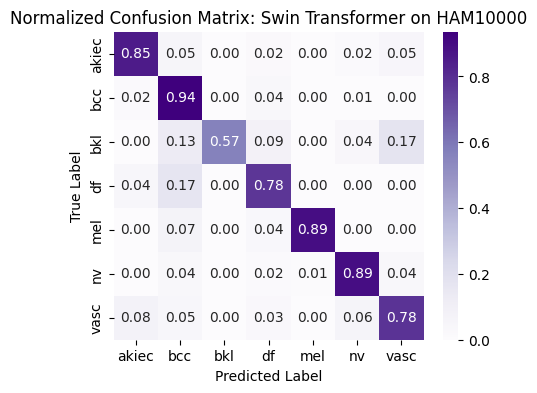


Classification Report:
              precision    recall  f1-score   support

       akiec       0.84      0.85      0.85       220
         bcc       0.95      0.94      0.94      1341
         bkl       0.93      0.57      0.70        23
          df       0.73      0.78      0.75       223
         mel       0.89      0.89      0.89        28
          nv       0.84      0.89      0.86       103
        vasc       0.70      0.78      0.74        65

    accuracy                           0.90      2003
   macro avg       0.84      0.81      0.82      2003
weighted avg       0.90      0.90      0.90      2003



In [13]:
class_names = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(all_labels, all_preds)

cm_norm = cm.astype("float")/cm.sum(axis=1)[:, np.newaxis]


plt.figure(figsize=(5,4))
sns.heatmap(
    cm_norm, 
    annot=True, 
    fmt='.2f', 
    cmap='Purples', 
    xticklabels=class_names, 
    yticklabels=class_names
)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Normalized Confusion Matrix: Swin Transformer on HAM10000')
plt.show()

print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))

In [14]:
# from sklearn.utils.class_weight import compute_class_weight
# import numpy as np

# class_weights = compute_class_weight(
#     class_weight="balanced",
#     classes=np.unique(train_df["label"]),
#     y=train_df["label"]
# )
# weight_tensor = torch.tensor(class_weights, dtype=torch.float)
# print(weight_tensor)

**SWIN MODEL**